# Project 3: Exploratory Analysis

**Data source:** CMIP6 → NCAR CESM2 → run `r10i1p1f1` (all graphs use the same run)

| Section | Variable | Table | Time range |
|---|---|---|---|
| 1. Temperature | `tas` – near-surface air temperature | `Amon` (monthly) | 1850–2100 |
| 2. The Arctic | `tas` – near-surface air temperature | `Amon` (monthly) | 1850–2100 |
| 2. The Arctic | `siarean` – Northern Hemisphere sea-ice area | `SImon` (monthly) | 1850–2014 only* |
| 3. Precipitation | `pr` – precipitation | `Amon` (monthly) | 1850–2100 |

- **1850–2014:** `historical` experiment (simulated past)
- **2015–2100:** `ssp245` projection (SSP2-4.5, middle emissions)

\*Sea-ice area is only available for the historical run.


*Requires:* `pip install xarray zarr gcsfs cftime nc-time-axis`

## Setup

In [2]:
# Libraries
import numpy as np
import pandas as pd
import xarray as xr
import gcsfs
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = 12, 6

/Users/amelia/ENTER/envs/dsc80/lib/python3.10/site-packages/google/api_core/_python_version_support.py:242: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)
/Users/amelia/ENTER/envs/dsc80/lib/python3.10/site-packages/google/api_core/_python_version_support.py:242: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.cloud._storage_v2 supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.cloud._storage_v2.
  warnings.warn(message, FutureWarning)
/Users/amelia/ENTER/envs/dsc80/lib/python3.10/site-packages/google/api_core/_python_version_support.py:242: FutureWarning: You are using a non-supported P

In [3]:
# Load CESM2 temperature: historical (1850–2014) + SSP2-4.5 projection (2015–2100)
df = pd.read_csv('https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv')   # catalog of all CMIP6 runs

hist = df.query("activity_id == 'CMIP' & source_id == 'CESM2' & experiment_id == 'historical' "
                "& table_id == 'Amon' & variable_id == 'tas'")
fut  = df.query("activity_id == 'ScenarioMIP' & source_id == 'CESM2' & experiment_id == 'ssp245' "
                "& table_id == 'Amon' & variable_id == 'tas'")

m = 'r10i1p1f1'   # run that exists in both historical and future (r1i1p1f1 has no future data)

gcs = gcsfs.GCSFileSystem(token='anon')
ds_hist = xr.open_zarr(gcs.get_mapper(hist.query("member_id == @m").zstore.values[0]), consolidated=True)
ds_fut  = xr.open_zarr(gcs.get_mapper(fut.query("member_id == @m").zstore.values[0]),  consolidated=True)
ds_all  = xr.concat([ds_hist, ds_fut], dim='time')

print(ds_all.time.values[0], '→', ds_all.time.values[-1])

1850-01-15 12:00:00 → 2100-12-15 12:00:00


In [ ]:
# Shared processing: yearly averages and change vs. the 1850–1900 average for every grid cell
annual = ds_all.tas.groupby('time.year').mean('time').compute()            # monthly → yearly, in Kelvin
annual = annual.assign_coords(lon=((annual.lon + 180) % 360) - 180).sortby('lon')   # 0–360 → -180–180 for a standard map

anom = annual - annual.sel(year=slice(1850, 1900)).mean('year')           # temperature change (°C) vs. 1850–1900

w = np.cos(np.deg2rad(anom.lat))                                           # weights: smaller grid cells near the poles count less
global_line = anom.weighted(w).mean(['lat', 'lon'])                        # global average change per year
arctic_line = anom.sel(lat=slice(66, 90)).weighted(w.sel(lat=slice(66, 90))).mean(['lat', 'lon'])   # Arctic (66–90°N)

## Exploratory graphs

### 1. Temperature

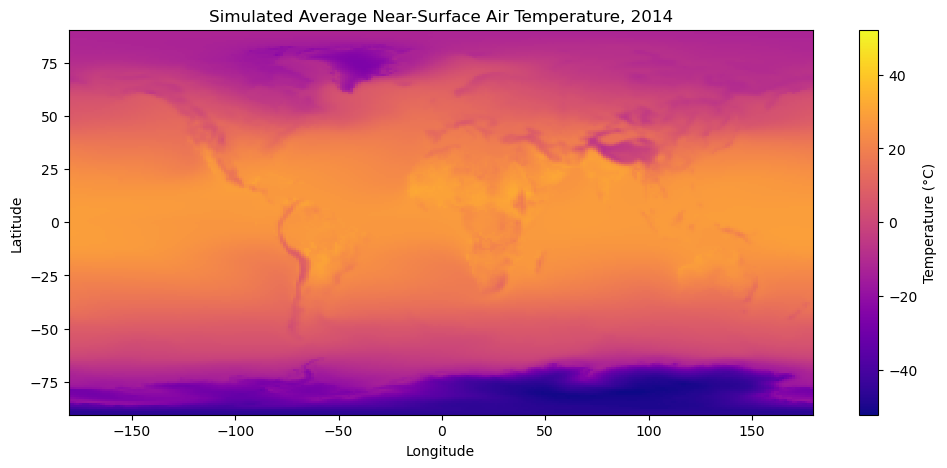

In [ ]:
# Map of the average temperature in 2014 (shows raw temperature mostly reflects geography)
(annual.sel(year=2014) - 273.15).plot(
    x='lon', y='lat', figsize=(12, 5), cmap='plasma',
    cbar_kwargs={'label': 'Temperature (°C)'},
)
plt.title('Simulated Average Near-Surface Air Temperature, 2014')
plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.show()

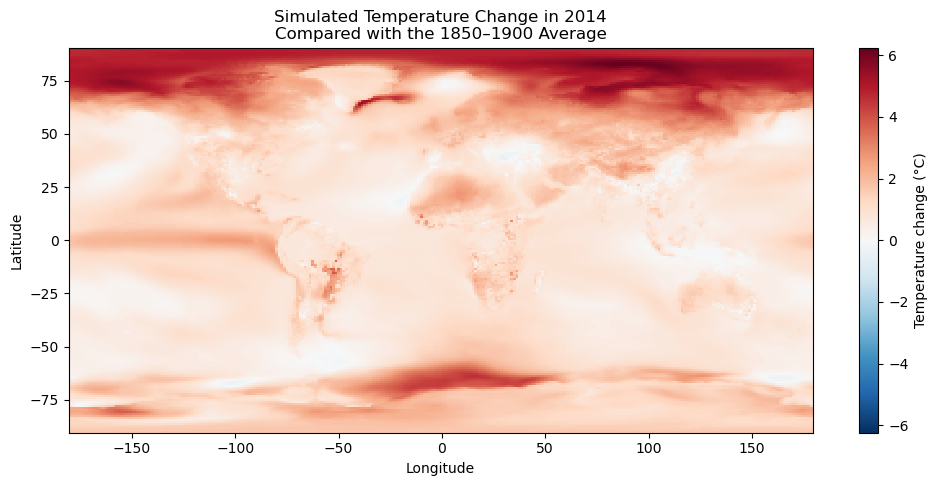

In [ ]:
# Map of how much each location warmed in 2014 compared with its 1850–1900 average (shows where the Earth warmed most)
anom.sel(year=2014).plot(
    x='lon', y='lat', figsize=(12, 5), cmap='RdBu_r', center=0,
    cbar_kwargs={'label': 'Temperature change (°C)'},
)
plt.title('Simulated Temperature Change in 2014\nCompared with the 1850–1900 Average')
plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.show()

### 2. The Artic

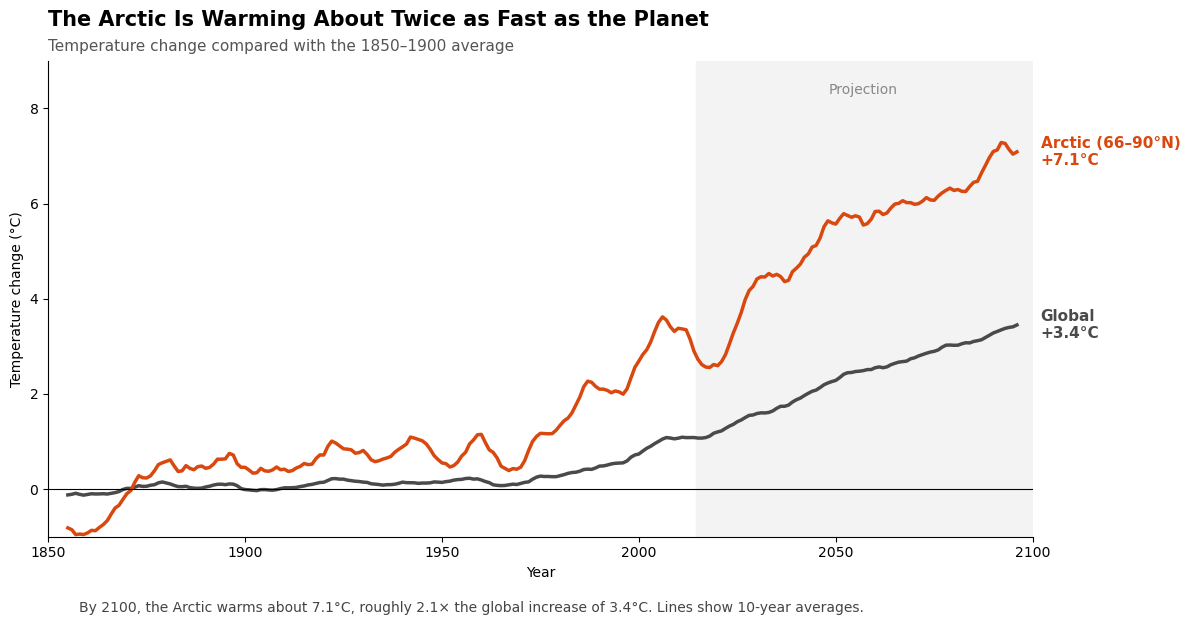

In [8]:
# Arctic vs. global temperature change, 1850–2100 (shows the Arctic warming about 2× faster than the planet overall)
global_smooth = global_line.rolling(year=10, center=True).mean()   # 10-year averages for smooth lines
arctic_smooth = arctic_line.rolling(year=10, center=True).mean()

g_end = float(global_line.sel(year=slice(2091, 2100)).mean())     # values near 2100 for labels
a_end = float(arctic_line.sel(year=slice(2091, 2100)).mean())
ratio = a_end / g_end

GLOBAL_COLOR = '#4a4a4a'   # dark gray
ARCTIC_COLOR = '#d9480f'   # warm red-orange

fig, ax = plt.subplots(figsize=(12, 6))

ax.axvspan(2014.5, 2100, color='#f3f3f3', zorder=0)               # shade the projection period
ax.text(2057, 8.3, 'Projection', ha='center', color='#888888', fontsize=10)

ax.plot(global_smooth.year, global_smooth, color=GLOBAL_COLOR, linewidth=2.5)
ax.plot(arctic_smooth.year, arctic_smooth, color=ARCTIC_COLOR, linewidth=2.5)
ax.axhline(0, color='black', linewidth=0.8)                         # 0 = the 1850–1900 average

ax.text(2102, arctic_smooth.dropna('year')[-1], f'Arctic (66–90°N)\n+{a_end:.1f}°C',
        color=ARCTIC_COLOR, fontsize=11, fontweight='bold', va='center')
ax.text(2102, global_smooth.dropna('year')[-1], f'Global\n+{g_end:.1f}°C',
        color=GLOBAL_COLOR, fontsize=11, fontweight='bold', va='center')

ax.set_title('The Arctic Is Warming About Twice as Fast as the Planet',
             fontsize=15, fontweight='bold', loc='left', pad=25)
ax.text(0, 1.02, 'Temperature change compared with the 1850–1900 average',
        transform=ax.transAxes, fontsize=11, color='#555555')
ax.set_xlabel('Year'); ax.set_ylabel('Temperature change (°C)')
ax.set_xlim(1850, 2100); ax.set_ylim(-1, 9)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

caption = (f'By 2100, the Arctic warms about {a_end:.1f}°C, roughly {ratio:.1f}× '
           f'the global increase of {g_end:.1f}°C. Lines show 10-year averages.')
fig.text(0.07, -0.01, caption, fontsize=10, color='#444444', va='top')

plt.tight_layout()
plt.show()

In [ ]:
# Helper function: load a CESM2 variable for 1850–2100 (historical + SSP2-4.5 joined)
def load_var(var, table='Amon', m='r10i1p1f1'):
    q = f"source_id == 'CESM2' & member_id == '{m}' & table_id == '{table}' & variable_id == '{var}'"
    h = df.query(q + " & experiment_id == 'historical'").zstore.values[0]
    f = df.query(q + " & experiment_id == 'ssp245'").zstore.values[0]
    return xr.concat([xr.open_zarr(gcs.get_mapper(h), consolidated=True),
                      xr.open_zarr(gcs.get_mapper(f), consolidated=True)], dim='time')

1e6 km2


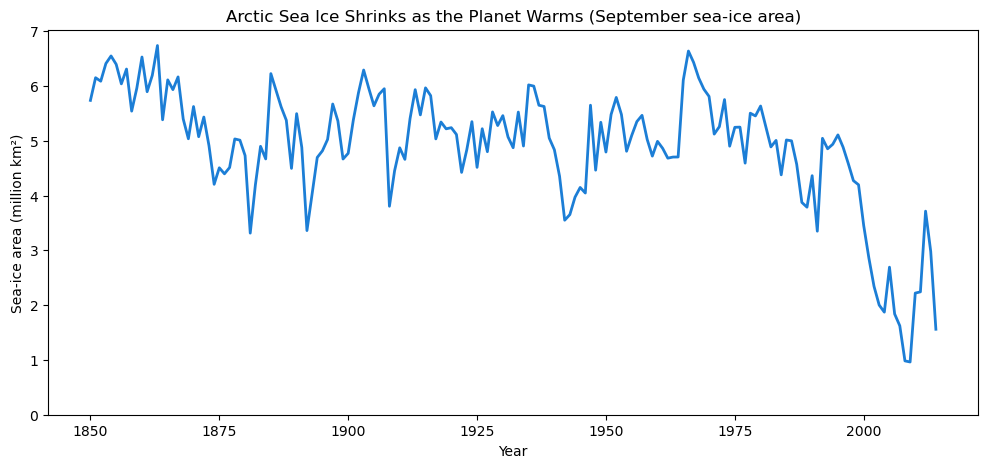

In [18]:
# Arctic sea-ice area every September, 1850–2014 
z = df.query("source_id == 'CESM2' & member_id == 'r10i1p1f1' & variable_id == 'siarean' "
             "& experiment_id == 'historical'").zstore.values[0]
ice_area = xr.open_zarr(gcs.get_mapper(z), consolidated=True).siarean
print(ice_area.attrs.get('units'))   # check units

sept_area = ice_area.sel(time=ice_area.time.dt.month == 9).groupby('time.year').mean().compute()

plt.figure(figsize=(12, 5))
plt.plot(sept_area.year, sept_area, color='#1c7ed6', linewidth=2)
plt.title('Arctic Sea Ice Shrinks as the Planet Warms (September sea-ice area)')
plt.xlabel('Year'); plt.ylabel('Sea-ice area (million km²)')
plt.ylim(bottom=0)
plt.show()

### 3. Precipitation

In [14]:
# Load precipitation (pr) for 1850–2100 and convert to yearly averages in mm/day
ds_pr = load_var('pr')                                                         # same run as temperature (r10i1p1f1)
pr_annual = ds_pr.pr.groupby('time.year').mean('time') * 86400                 # kg/m²/s → mm/day
pr_annual = pr_annual.assign_coords(lon=((pr_annual.lon + 180) % 360) - 180).sortby('lon')
pr_annual = pr_annual.compute()

pr_base = pr_annual.sel(year=slice(1850, 1900)).mean('year')                   # 1850–1900 average rainfall

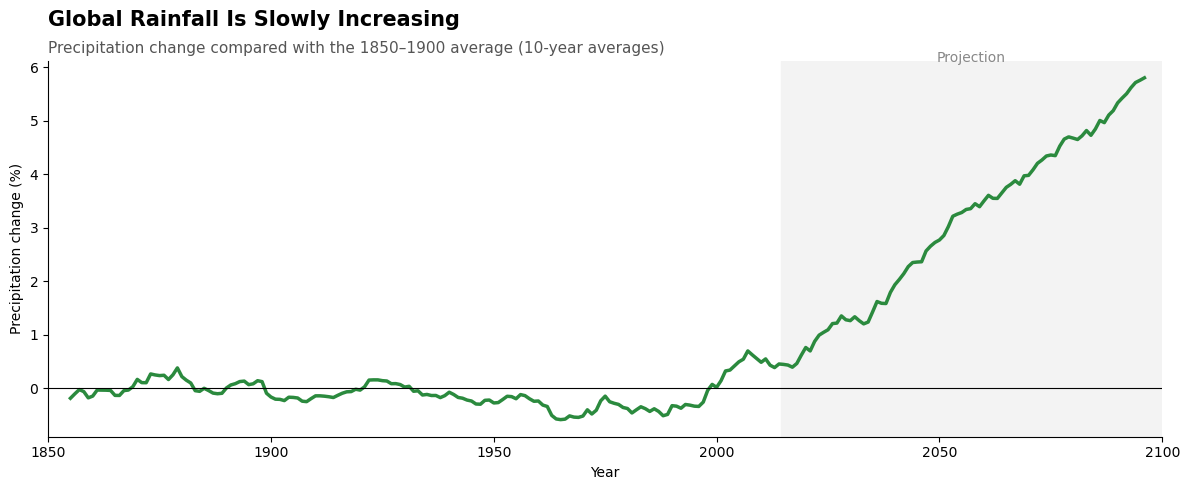

In [16]:
# Global average rainfall change, 1850–2100, vs. 1850–1900 (shows rainfall rising overall as the planet warms)
w_pr = np.cos(np.deg2rad(pr_annual.lat))
pr_global = pr_annual.weighted(w_pr).mean(['lat', 'lon'])
pr_global_pct = (pr_global / pr_global.sel(year=slice(1850, 1900)).mean() - 1) * 100
pr_smooth = pr_global_pct.rolling(year=10, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.axvspan(2014.5, 2100, color='#f3f3f3', zorder=0)
ax.text(2057, pr_smooth.max() * 1.05, 'Projection', ha='center', color='#888888', fontsize=10)
ax.plot(pr_smooth.year, pr_smooth, color='#2b8a3e', linewidth=2.5)            # green for rain
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Global Rainfall Is Slowly Increasing', fontsize=15, fontweight='bold', loc='left', pad=25)
ax.text(0, 1.02, 'Precipitation change compared with the 1850–1900 average (10-year averages)',
        transform=ax.transAxes, fontsize=11, color='#555555')
ax.set_xlabel('Year'); ax.set_ylabel('Precipitation change (%)')
ax.set_xlim(1850, 2100)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()